# ***Trabajo práctico N° 2 - Minería de datos (TUIA)***
## **Alumnos: Gastón Rinaldi y Aldana Desiré Sánchez**
### Año 2026
### Profesores:
- Dr. Ing. Flavio E. Spetale (Resp. Cátedra)
- Dr. Bioing. Ramiro Gatti
- Tec. en IA Julieta López Ceratto


## Librerías

In [1]:
# Datos y gráficos
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Modelos
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB

# Preprocesamiento y pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer

# Particiones y selección de hiperparámetros
from sklearn.model_selection import (train_test_split, GridSearchCV,
                                     KFold, StratifiedKFold, cross_val_score)

# Métricas
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

# **Parte A – Regresión**
Dataset sobre comportamiento financiero de 1000 empresas.

Objetivo: estimación de la variable Profit.

In [2]:
# Los CSV están en la misma carpeta que este notebook.
# En Google Colab: subí los archivos desde el panel lateral (o montá Drive y ajustá la ruta).


In [3]:
# Lectura de CSV
df = pd.read_csv('1000_Companies.csv')

In [4]:
# Primer vistazo al DataFrame resultande
df.head()

,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


## EDA (Analisis Exploratorio de Datos)

In [5]:
# Informacion sobre cantidad de entradas, variables, tipos de datos.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 39.2 KB


Observación: no hay valores faltantes (1000 filas, y 1000 entradas no nulas en todas las columnas).

In [6]:
# Distribuciones
df.describe()

,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


Ninguna celda posee valores negativos, y como hablamos de dinero significa que hasta el momento no se identifican grandes errores de carga de datos.

### Variables y sus significados:
1. R&D Spend (Research and Development Spend): Gasto en Investigación y Desarrollo. Es el dinero que la empresa invierte en crear nuevos productos, mejorar procesos, innovación, etc.
2. Administration: Gastos administrativos. Incluye salarios administrativos, gestión, recursos humanos, contabilidad, oficinas y otros costes de administración.Marketing
3. Spend: Gasto en marketing y publicidad. Es el dinero destinado a promocionar productos o servicios para atraer clientes.
4. State: Estado o región donde se encuentra la empresa. Es una variable categórica.
5. Profit: Beneficio o ganancia obtenida por la empresa. Es la variable objetivo que se intenta predecir.


In [7]:
# Convertimos 'State' en variable categorica
df['State'] = df['State'].astype('category')

# Redondeamos a 2 decimales todas las numericas ya que hablamos de centavos
df[df.select_dtypes(include='number').columns] = (df.select_dtypes(include='number').round(2))

# Corroboramos:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   RyD_Spend       1000 non-null   float64 
 1   Administration  1000 non-null   float64 
 2   MarketingSpend  1000 non-null   float64 
 3   State           1000 non-null   category
 4   Profit          1000 non-null   float64 
dtypes: category(1), float64(4)
memory usage: 32.4 KB


## Visualizaciones


### Variable categorica
- Gráfico de barras



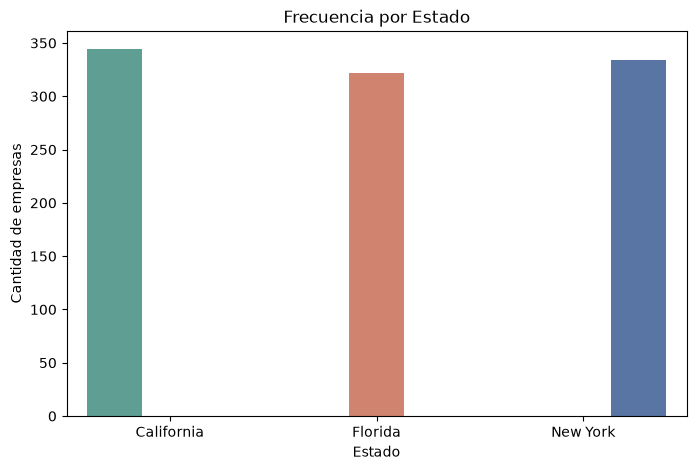

In [8]:
# Paleta de colores por estado
paleta_estados = {
    'New York': '#4C72B0',    # azul
    'California': '#55A89A',  # verde azulado
    'Florida': '#E07A5F'      # coral
}

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='State', hue='State',
              palette=paleta_estados, legend=False)

plt.title('Frecuencia por Estado')
plt.xlabel('Estado')
plt.ylabel('Cantidad de empresas')
plt.show()

In [9]:
# Corroboramos cantidad exacta de entradas por estado
df.groupby('State').size()

State
California    344
Florida       322
New York      334
dtype: int64

- Boxplot en relacion a la variable a predecir: Profit

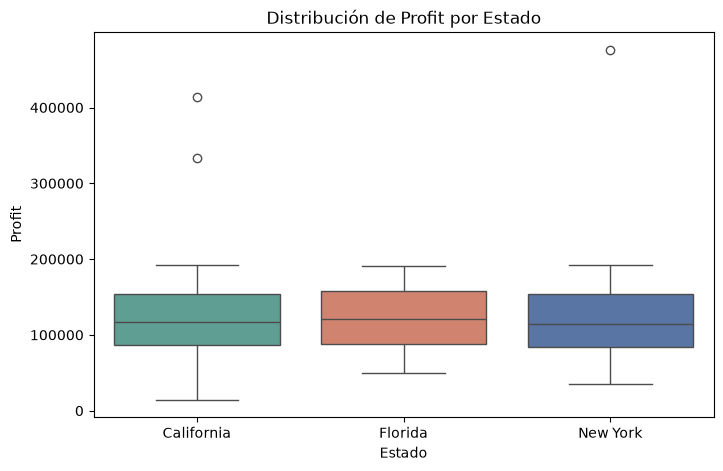

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='State',
    y='Profit',
    palette=paleta_estados
)

plt.title('Distribución de Profit por Estado')
plt.xlabel('Estado')
plt.ylabel('Profit')

plt.show()

Observamos en este grafico que hay 3 empresas con ganancias tan elevadas que se consideran outliers, 2 en California y 1 en Nueva York.

### Variables numericas
- Boxplots e histogramas

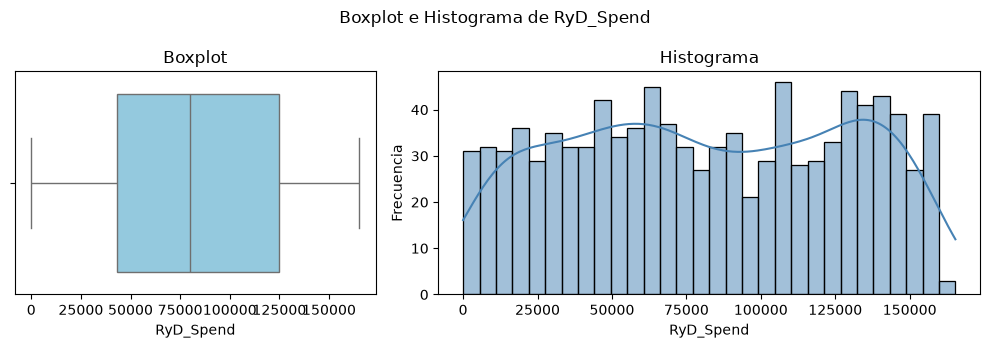

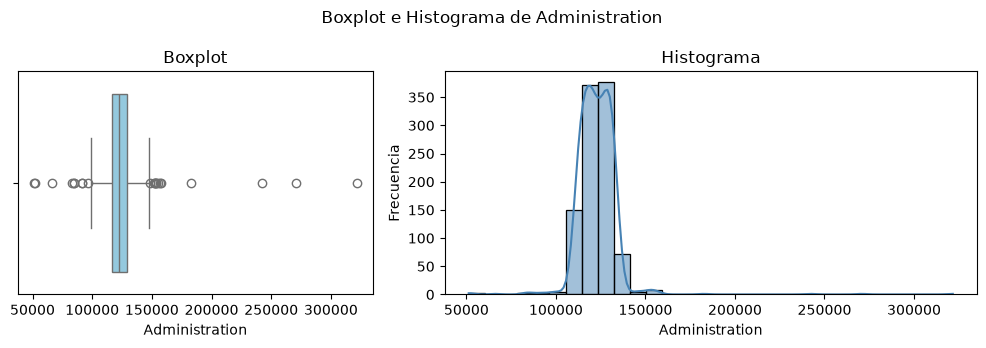

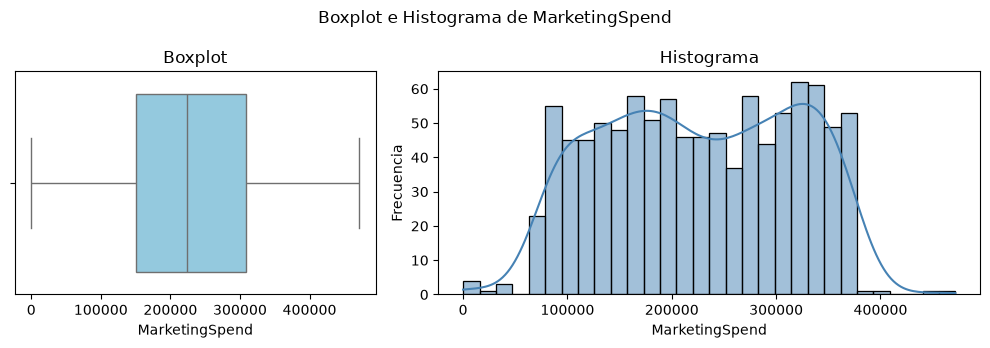

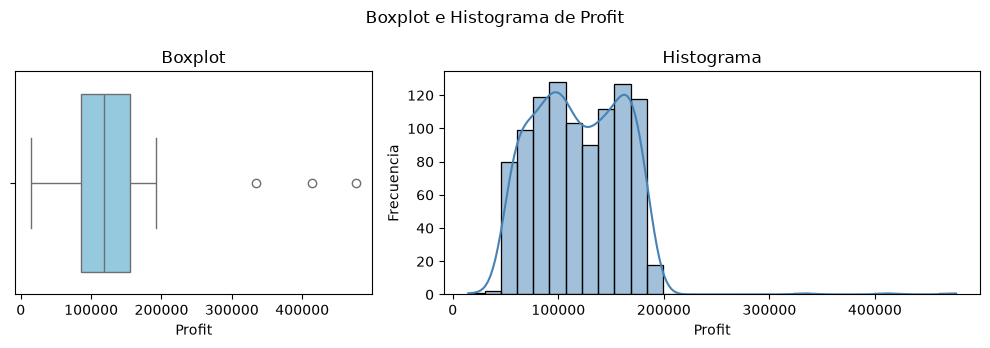

In [11]:
# Variables numéricas
variables_numericas = ['RyD_Spend', 'Administration', 'MarketingSpend', 'Profit']

for col in variables_numericas:
    fig, axes = plt.subplots(
        ncols=2,
        figsize=(10, 3.5),
        sharex=True,
        gridspec_kw={'width_ratios': [2, 3]})

    fig.suptitle(f'Boxplot e Histograma de {col}', fontsize=12)

    # Boxplot horizontal
    sns.boxplot(x=df[col], ax=axes[0], color='skyblue')
    axes[0].set_title('Boxplot')
    axes[0].set_xlabel(col)

    # Histograma
    sns.histplot(df[col], kde=True, bins=30, ax=axes[1], color='steelblue')
    axes[1].set_title('Histograma')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Frecuencia')

    plt.tight_layout()
    plt.show()

Observamos 3 outliers muy por fuera de lo normal en Administracion y en Profit. Como el numero de outliers cincide con los encontrados en la variable categorica, es importante ubicar si se refieren a las mismas empresas:

In [12]:
df.sort_values('Profit', ascending=False)[['State', 'Administration', 'Profit']].head(3)

,State,Administration,Profit
999,New York,270939.86,476485.43
997,California,241926.31,413956.48
998,California,321652.14,333962.19


Efectivamente esos 3 outliers que detectamos desde el primer grafico coinciden con los hallados en los boxplots.

Parecen ser 3 casos particulares de empresas con muy altas ganancias, mayor gasto en administracion y son exactamente las 2 detectadas en California y la detectada en Nueva York.

- Pairplot con KDE en la diagonal

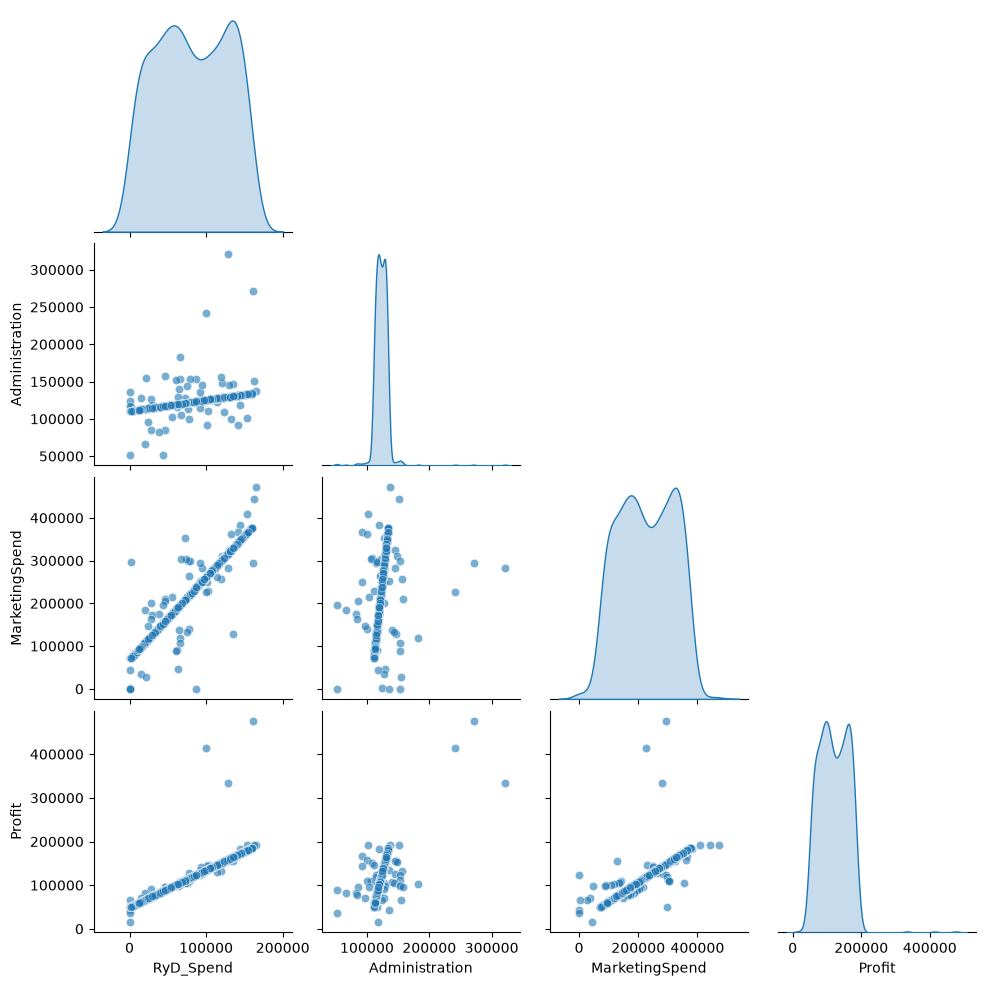

In [13]:
sns.pairplot(
    df[variables_numericas],
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.6})
plt.show()

Observamos patrones lineales fuertemente marcados en todas las relaciones entre variables. Si bien hay algunos puntos por fuera de esa linea, se dibujan muy claramente relaciones lineales positivas entre todas las variables.

### Correlaciones - Pearson y Spearman

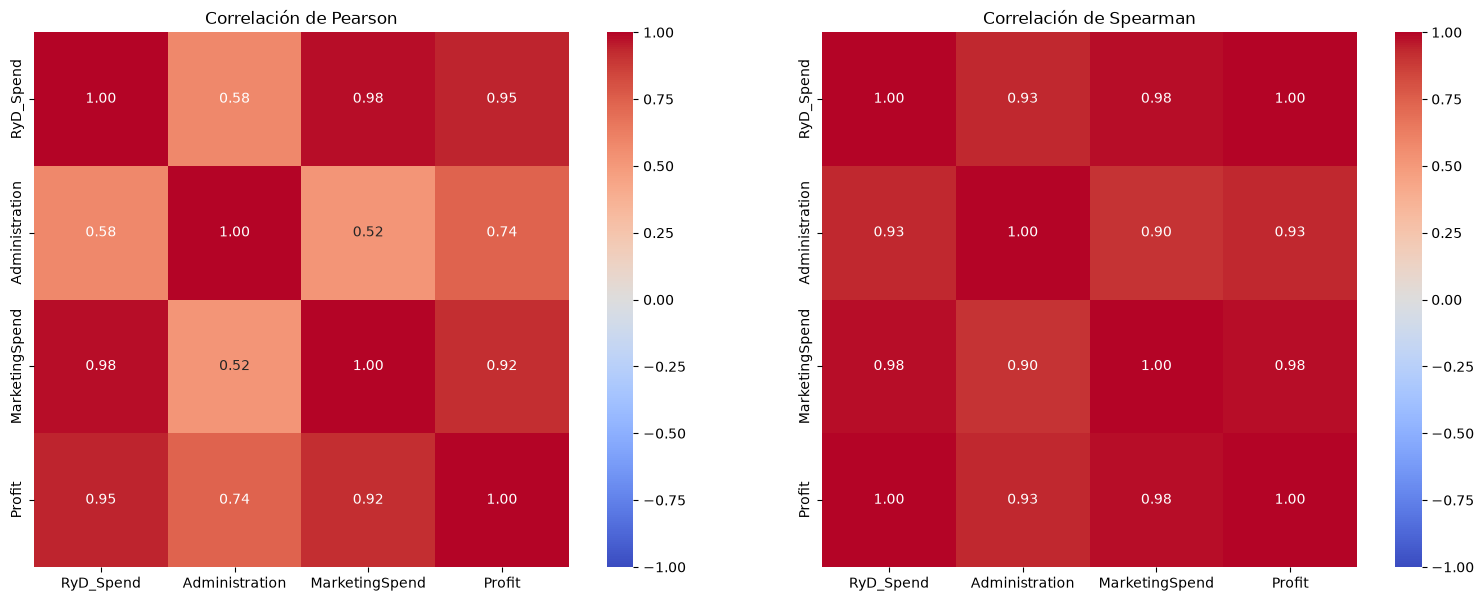

In [14]:
# Matrices de correlación
corr_pearson = df[variables_numericas].corr(method='pearson') # lineales
corr_spearman = df[variables_numericas].corr(method='spearman') # monótonas, incluso si no son lineales.

# Crear figura
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pearson
sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[0])
axes[0].set_title('Correlación de Pearson')

# Spearman
sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[1])
axes[1].set_title('Correlación de Spearman')

plt.tight_layout()
plt.show()

Confirmamos aquí lo sospechado anteriormente: todas las variables están muy correlacionadas entre sí (según la matriz de Spearman).

Particularmente la correlación más fuerte se da en Spearman entre la variable a predecir, Profit, y RyD_Spend: es monótona positiva perfecta entre ambas variables.
Tambien MarketingSpend y Profit están extremadamente relacionadas con un 0.98 de correlacion de Spearman.

## Limpieza y preparación de datos

Tanto para arboles de decision por regresion como por clasificacion los datos no necesitan ser normalizados o estandarizados; pueden usarse tal como están.

In [15]:
# Eliminamos las 3 empresas que representan outliers (mayor Profit)
indices = df.nlargest(3, 'Profit').index
df = df.drop(indices)

Como RyD_Spend y MarketingSpend estan fuertemente correlacionadas entre sí; y a su vez, si bien ambas estan muy correlacionadas con Profit, RyD_Spend es todavía mejor predictora, decidimos excluir del modelo a la variable MarketingSpend con le objetivo de reducir la dimensionalidad del problema:

In [16]:
df = df.drop(columns=['MarketingSpend'])

## Árbol de decisión

In [17]:
# Variable objetivo y predictoras
X = df.drop(columns=['Profit'])
y = df['Profit']

# Aplicamos One-Hot Encoding a la variable categórica 'State' para aplicar DecisionTreeRegressor
X_encoded = pd.get_dummies(X, columns=['State'], drop_first=True)

# Selección del espacio de búsqueda de hiperparámetros
param_grid = {
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 5, 10]}

### Split train/test y val/prueba
Separamos el conjunto total de datos en train y test, y luego dividimos el conjunto de test en validacion y prueba.

In [18]:
# 70/30
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X_encoded, y, test_size=0.30, random_state=63)
### 30 -> 15/15
X_val_15, X_prueba_15, y_val_15, y_prueba_15 = train_test_split(
    X_test_30, y_test_30, test_size=0.5, random_state=63)

# 80/20
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X_encoded, y, test_size=0.20, random_state=63)
### 20 -> 10/10
X_val_10, X_prueba_10, y_val_10, y_prueba_10 = train_test_split(
    X_test_20, y_test_20, test_size=0.5, random_state=63)

### Generacion de modelos

In [19]:
X = df.drop(columns=['Profit'])
y = df['Profit']
X_encoded = pd.get_dummies(X, columns=['State'], drop_first=True)

param_grid = {
    'max_depth': [3, 5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5, 10]}

cv_reg = KFold(n_splits=5, shuffle=True, random_state=63)
modelos_reg, res_reg = {}, []

for nombre, t in {'80/20': 0.20, '70/30': 0.30}.items():
    X_tr, X_ts, y_tr, y_ts = train_test_split(X_encoded, y, test_size=t, random_state=63)
    gs = GridSearchCV(DecisionTreeRegressor(random_state=63), param_grid,
                      cv=cv_reg, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_tr, y_tr)
    pred = gs.predict(X_ts)
    mse = mean_squared_error(y_ts, pred)
    res_reg.append({'Partición': nombre,
                    'Mejores params': gs.best_params_,
                    'RMSE CV (train)': round(-gs.best_score_, 2),
                    'MAE test': round(mean_absolute_error(y_ts, pred), 2),
                    'MSE test': round(mse, 2),
                    'RMSE test': round(np.sqrt(mse), 2)})
    modelos_reg[nombre] = (gs, X_ts, y_ts, pred)

display(pd.DataFrame(res_reg))

,Partición,Mejores params,RMSE CV (train),MAE test,MSE test,RMSE test
0,80/20,"{'max_depth': 10, 'min_samples_leaf': 5, 'min_...",2033.45,1117.05,12692424.80,3562.64
1,70/30,"{'max_depth': 10, 'min_samples_leaf': 2, 'min_...",2322.07,787.67,7037940.95,2652.91


### Selección del mejor modelo

Comparamos los modelos evaluando todos los parámetros, con ambas divisiones train/test, y descubrimos que el modelo que mejor predice (menor RMSE en test) corresponde a:
**split 70/30 con max_depth=10, min_samples_split=2 y min_samples_leaf=2**.

Generamos y guardamos este modelo para comenzar con las pruebas:

In [20]:
tree_reg = DecisionTreeRegressor(max_depth=10, criterion='squared_error',
                                 min_samples_leaf=2, min_samples_split=2,
                                 random_state=63)
tree_reg.fit(X_train_70, y_train_70)

# Predicciones sobre el conjunto de validación (15%)
pred_val_70_30 = tree_reg.predict(X_val_15)


## Graficos

Comparamos los valores predichos por el modelo con los reales (conjunto val):

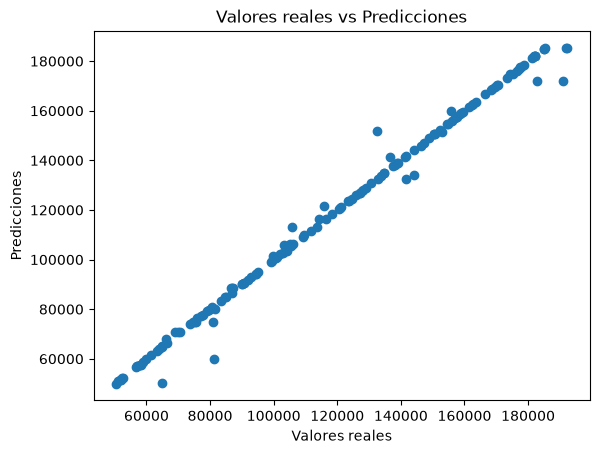

In [21]:
# Graficar valores reales vs predicciones
plt.scatter(y_val_15, pred_val_70_30)
plt.xlabel("Valores reales")
plt.ylabel("Predicciones")
plt.title("Valores reales vs Predicciones")
plt.show()

Como podemos observar, es una MUY buena predicción.

A continuación graficaremos la estructura del Árbol de decision del mejor modelo obtenido:

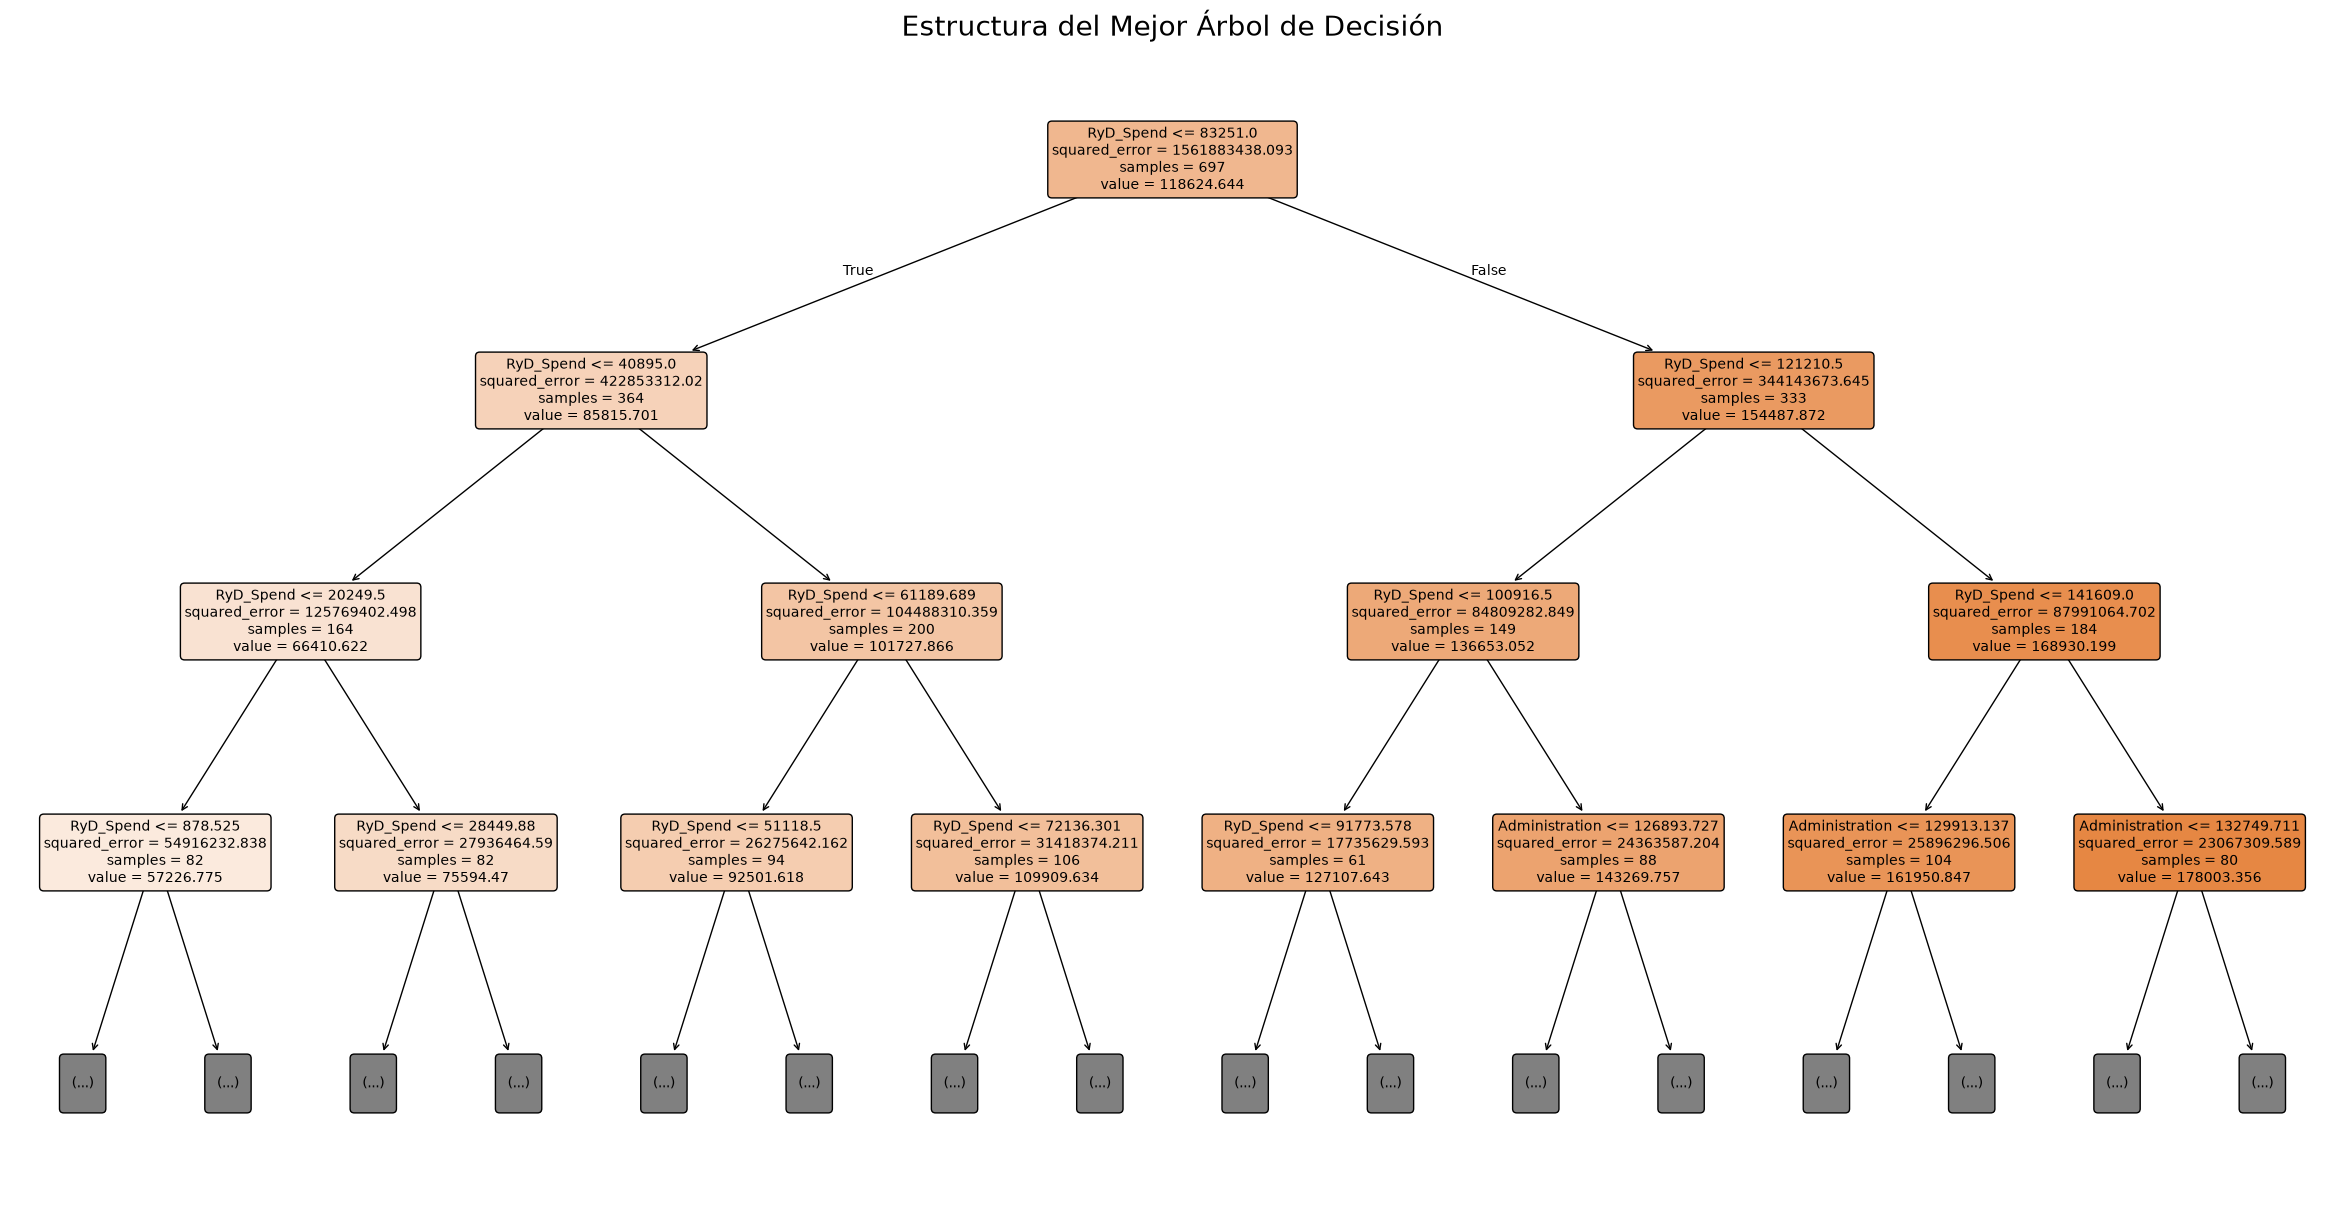

In [22]:
# Obtenemos los nombres de las variables predictoras del conjunto codificado
features = X_encoded.columns

# Gráfico del árbol de decisión (limitado a profundidad 3 para poder visualizarlo con claridad)
plt.figure(figsize=(30, 15))
plot_tree(
    tree_reg,
    feature_names=features,
    fontsize=10,
    filled=True,
    rounded=True,
    max_depth=3
)
plt.title("Estructura del Mejor Árbol de Decisión", fontsize=20)
plt.show()

Y en la siguiente visualización, podemos ver la estructura completa sin límites visuales:

In [23]:
tree_rules = export_text(tree_reg, feature_names=features)
print(tree_rules)

|--- RyD_Spend <= 83251.00
|   |--- RyD_Spend <= 40895.00
|   |   |--- RyD_Spend <= 20249.50
|   |   |   |--- RyD_Spend <= 878.52
|   |   |   |   |--- value: [30971.51]
|   |   |   |--- RyD_Spend >  878.52
|   |   |   |   |--- RyD_Spend <= 10788.50
|   |   |   |   |   |--- RyD_Spend <= 5729.50
|   |   |   |   |   |   |--- RyD_Spend <= 3454.00
|   |   |   |   |   |   |   |--- RyD_Spend <= 1970.50
|   |   |   |   |   |   |   |   |--- RyD_Spend <= 1292.23
|   |   |   |   |   |   |   |   |   |--- value: [50093.93]
|   |   |   |   |   |   |   |   |--- RyD_Spend >  1292.23
|   |   |   |   |   |   |   |   |   |--- value: [49959.78]
|   |   |   |   |   |   |   |--- RyD_Spend >  1970.50
|   |   |   |   |   |   |   |   |--- Administration <= 110854.22
|   |   |   |   |   |   |   |   |   |--- Administration <= 110843.22
|   |   |   |   |   |   |   |   |   |   |--- value: [51130.18]
|   |   |   |   |   |   |   |   |   |--- Administration >  110843.22
|   |   |   |   |   |   |   |   |   |   |--- va

Visualizamos cuánto influye cada variable en la predicción:

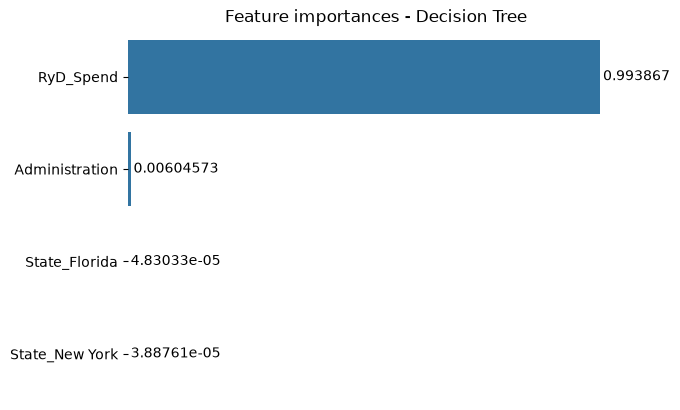

In [24]:
# Creo un df con dos columnas -> Caracteristica y ganacia de información
features_df = pd.DataFrame({'features': features,
                            'importances': tree_reg.feature_importances_ })

# Ordeno en base a la importancia
features_df_sorted = features_df.sort_values(by='importances', ascending=False)

g = sns.barplot(data=features_df_sorted, x='importances', y ='features')
sns.despine(bottom = True, left = True)
g.set_title('Feature importances - Decision Tree')
g.set(xlabel=None, ylabel=None, xticks=[])
for value in g.containers:
    g.bar_label(value, padding=2)

Tal como observamos en los graficos descriptivos del dataset, RyD_Spend es por mucho la variable que más explica Profit.

## Prueba final
Una vez que tenemos el mejor modelo, procedemos a utilizarlo con el conjunto de test que nos quedó pendiente, 'prueba', correspondiente a un total de 15% de los datos.

In [25]:
# Predecimos sobre el conjunto de test independiente (que el modelo NUNCA vio durante el tuning)
pred_test = tree_reg.predict(X_prueba_15)

# Calculamos las métricas más representativas
print('Error absoluto medio:', round(mean_absolute_error(y_prueba_15, pred_test), 2))
print('Error medio cuadrado:', round(mean_squared_error(y_prueba_15, pred_test), 2))
print('Raíz del error medio cuadrado:', round(np.sqrt(mean_squared_error(y_prueba_15,
                                                pred_test)), 2))

# Visualizamos los resultados
tableResult = pd.DataFrame({'Real': y_prueba_15, 'Predicción': pred_test})
tableResult['Predicción'] = tableResult['Predicción'].round(2)
tableResult.head(10)

Error absoluto medio: 339.97
Error medio cuadrado: 692046.08
Raíz del error medio cuadrado: 831.89


,Real,Predicción
335,121248.71,121236.76
236,68984.02,70865.32
267,117645.31,117727.04
571,184581.60,184535.90
149,121505.85,121236.76
625,77667.89,77701.49
522,54119.35,54225.28
108,151782.79,151576.34
598,65513.03,65567.70
511,98444.26,98314.83


## **Conclusión**
El mejor modelo de predicción hallado a través del método 'Árbol de decisión' con Regresión es para este dataset:
`DecisionTreeRegressor(max_depth=10, min_samples_leaf=2, min_samples_split=2, random_state=63)`

# Parte B – Clasificación
Dataset sobre pacientes con sus datos clínicos y una droga recetada.
Objetivo: predecir qué droga corresponde a cada paciente a partir de sus características.

In [26]:
# Lectura de CSV
df = pd.read_csv('drugType.csv')

In [27]:
# Primer vistazo al DataFrame resultande
df.head()

,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


## EDA (Analisis Exploratorio de Datos)

In [28]:
# Informacion sobre cantidad de entradas, variables, tipos de datos.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


Observación: no hay valores faltantes (200 filas, y 200 entradas no nulas en todas las columnas).

In [29]:
# Distribuciones (solo variables numericas)
df.describe()

,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


Ninguna celda posee valores negativos, y como hablamos de edades esto tiene sentido. La segunda columna hace referencia a un calculo que se hace por paciente sobre sodio y potasio, por lo que tambien está perfecto que sea positivo (una persona no podría tener ni sodio ni potasio negativo).

### Variables y sus significados:
1. Edad: edad del paciente en años. Unica variable numerica entera.
2. Sexo: F (femenino) o M (masculino).
3. BP: Blood Pressure, presión arterial. Categórica: Bajo, Normal, Alto.
4. Colesterol: nivel de colesterol. Categórica: Normal o Alto.
5. Na_a_K: relación entre sodio (Na) y potasio (K) en sangre, como cociente. Unica variable numerica continua.
6. Droga: la variable objetivo. Si bien no corresponden a medicamentos reales, representan las drogas recetadas a cada paciente.

In [30]:
# Convertimos 'Sexo', 'BP', 'Colesterol' y 'Droga' en variables categoricas
df['Sexo'] = df['Sexo'].astype('category')
df['BP'] = df['BP'].astype('category')
df['Colesterol'] = df['Colesterol'].astype('category')
df['Droga'] = df['Droga'].astype('category')

# Redondeamos a 2 decimales la variable numérica para simplificar los calculos
df['Na_a_K'] = df['Na_a_K'].round(2)

# Corroboramos:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Edad        200 non-null    int64   
 1   Sexo        200 non-null    category
 2   BP          200 non-null    category
 3   Colesterol  200 non-null    category
 4   Na_a_K      200 non-null    float64 
 5   Droga       200 non-null    category
dtypes: category(4), float64(1), int64(1)
memory usage: 4.1 KB


## Visualizaciones

### Variables categoricas
- Gráfico de barras

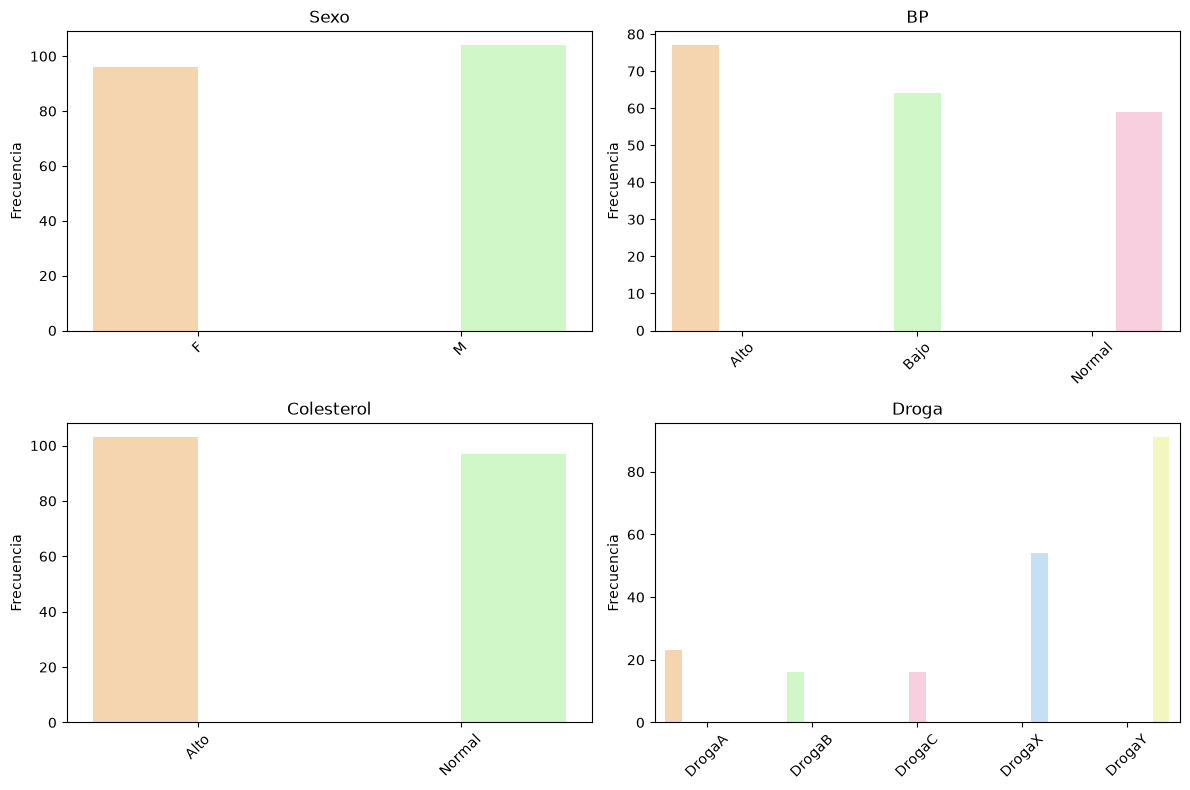

In [31]:
# Paleta de colores genérica en tonos pastel
paleta_pastel = [
    "#FFD6A5",  # naranja pastel
    "#CAFFBF",  # verde pastel
    "#FFC8DD",  # rosa pastel
    "#BDE0FE",  # celeste pastel
    "#FDFFB6"]  # amarillo pastel

variables_cat = ['Sexo', 'BP', 'Colesterol', 'Droga']

ncols = 2
nrows = math.ceil(len(variables_cat) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4*nrows))
axes = axes.flatten()

for i, var in enumerate(variables_cat):
    sns.countplot(
        data=df,
        x=var,
        hue=var,
        palette=paleta_pastel,
        legend=False,
        ax=axes[i])

    axes[i].set_title(var)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [32]:
# Corroboramos cantidad exacta de entradas variable categórica

df.groupby('Sexo').size()

Sexo
F     96
M    104
dtype: int64

In [33]:
df.groupby('BP').size()

BP
Alto      77
Bajo      64
Normal    59
dtype: int64

In [34]:
df.groupby('Colesterol').size()

Colesterol
Alto      103
Normal     97
dtype: int64

In [35]:
df.groupby('Droga').size()

Droga
DrogaA    23
DrogaB    16
DrogaC    16
DrogaX    54
DrogaY    91
dtype: int64

### Variables numericas
- Boxplots e histogramas

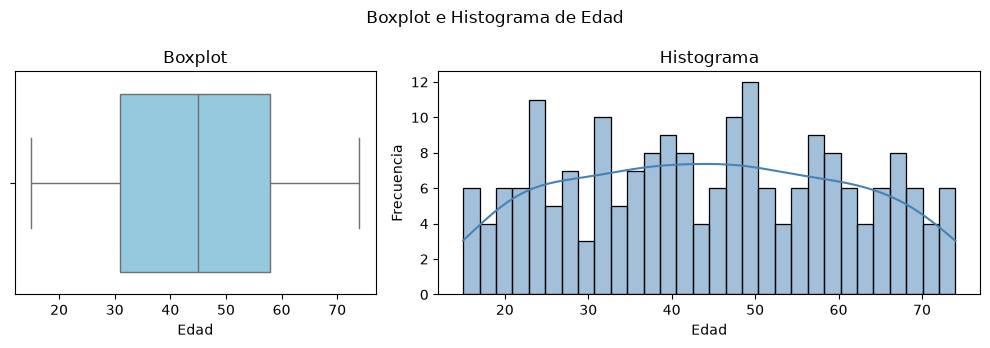

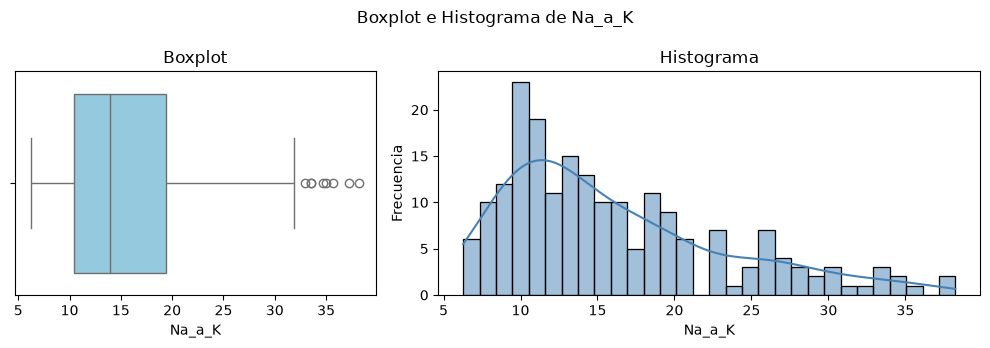

In [36]:
# Variables numéricas
variables_numericas = ['Edad', 'Na_a_K']

for col in variables_numericas:
    fig, axes = plt.subplots(
        ncols=2,
        figsize=(10, 3.5),
        sharex=True,
        gridspec_kw={'width_ratios': [2, 3]})
    fig.suptitle(f'Boxplot e Histograma de {col}', fontsize=12)

    # Boxplot horizontal
    sns.boxplot(x=df[col], ax=axes[0], color='skyblue')
    axes[0].set_title('Boxplot')
    axes[0].set_xlabel(col)

    # Histograma
    sns.histplot(df[col], kde=True, bins=30, ax=axes[1], color='steelblue')
    axes[1].set_title('Histograma')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Frecuencia')

    plt.tight_layout()
    plt.show()

Podemos observar outliers en Na_a_K, pero omitirlos implicaría sgar el estudio sistemáticamente: puede que las drogas asignadas a cada paciente sean específicas de su condición. Es por esto que decidimos dejarlas.

## Limpieza y preparación de datos
DecisionTreeClassifier solo acepta features numéricas. Por ende codificaremos todas las variables categóricas, excepto por la objetivo, ya que el clasificador lo maneja solo.


In [37]:
# BP y Colesterol tienen un orden natural, así que un ordinal tiene sentido y es más simple de interpretar en el árbol
df['BP'] = df['BP'].map({'Bajo': 0, 'Normal': 1, 'Alto': 2})
df['Colesterol'] = df['Colesterol'].map({'Normal': 0, 'Alto': 1})

# Sexo es binaria
df['Sexo'] = df['Sexo'].map({'F': 0, 'M': 1})

## Árbol de decisión

In [38]:
# Borro las variables viejas del namespace para poder reutilizar los nombres
for v in ['X_train_70', 'X_test_30', 'y_train_70', 'y_test_30', 'X_encoded', 'y',
          'X_val_15', 'X_prueba_15', 'y_val_15', 'y_prueba_15',
          'X_train_80', 'X_test_20', 'y_train_80', 'y_test_20',
          'X_val_10', 'X_prueba_10', 'y_val_10', 'y_prueba_10',
          'results_list_70_30']:
    globals().pop(v, None)

In [39]:
# Separación de características y variable objetivo
X = df.drop('Droga', axis=1)
y = df['Droga']

# Partición 1: 80% entrenamiento / 20% prueba (estratificada)
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X, y, test_size=0.20, random_state=63, shuffle=True, stratify=y
)

# Partición 2: 70% entrenamiento / 30% prueba (estratificada)
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X, y, test_size=0.30, random_state=63, shuffle=True, stratify=y
)

print(f"Dimensiones Partición 80/20 -> Train: {X_train_80.shape}, Test: {X_test_20.shape}")
print(f"Dimensiones Partición 70/30 -> Train: {X_train_70.shape}, Test: {X_test_30.shape}")

Dimensiones Partición 80/20 -> Train: (160, 5), Test: (40, 5)
Dimensiones Partición 70/30 -> Train: (140, 5), Test: (60, 5)


### 4.1. Exploración sistemática de hiperparámetros (Pre-poda)
Se realiza una búsqueda en grilla exhaustiva utilizando validación cruzada estratificada (5 folds) sobre el conjunto de entrenamiento de la partición 80/20. Se exploran sistemáticamente:
- `max_depth`: [2, 3, 4, 6] (4 valores)
- `min_samples_split`: [2, 5, 10] (3 valores)
- `min_samples_leaf`: [1, 2, 4] (3 valores)

Se utiliza `scoring='f1_macro'` para priorizar el rendimiento equilibrado sobre todas las clases farmacéuticas, contrarrestando el desbalance natural de `DrogaB` y `DrogaC`.

In [40]:
# Grilla de hiperparámetros a explorar
param_grid_tree = {
    'max_depth': [2, 3, 4, 6],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Validación cruzada estratificada con random_state=63
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=63)

grid_tree = GridSearchCV(
    estimator=DecisionTreeClassifier(criterion='gini', random_state=63),
    param_grid=param_grid_tree,
    cv=cv_strat,
    scoring='f1_macro',
    n_jobs=-1
)

# Ajuste con los datos de entrenamiento
grid_tree.fit(X_train_80, y_train_80)

# Resumen de resultados
df_grid_cv = pd.DataFrame(grid_tree.cv_results_)
mejores_configs = df_grid_cv[['param_max_depth', 'param_min_samples_split', 'param_min_samples_leaf', 'mean_test_score', 'std_test_score']]
mejores_configs = mejores_configs.sort_values(by='mean_test_score', ascending=False).head(5)
mejores_configs.rename(columns={'mean_test_score': 'F1 Macro CV Promedio', 'std_test_score': 'Desvío'}, inplace=True)

print("Mejores hiperparámetros encontrados en CV:")
for k, v in grid_tree.best_params_.items():
    print(f" - {k}: {v}")

display(mejores_configs)

# Guardamos el mejor árbol obtenido antes de post-poda
arbol_sin_podar = grid_tree.best_estimator_

Mejores hiperparámetros encontrados en CV:
 - max_depth: 4
 - min_samples_leaf: 1
 - min_samples_split: 2


,param_max_depth,param_min_samples_split,param_min_samples_leaf,F1 Macro CV Promedio,Desvío
32,6,10,2,0.982329,0.026579
33,6,2,4,0.982329,0.026579
18,4,2,1,0.982329,0.026579
19,4,5,1,0.982329,0.026579
34,6,5,4,0.982329,0.026579


### 4.2. Análisis de Post-poda (Cost-Complexity Pruning)
A partir de la estructura del árbol óptimo inicial, se calcula la ruta de poda por complejidad de costo (`cost_complexity_pruning_path`). Esto permite obtener los valores efectivos de $\alpha$ (`ccp_alpha`) en los cuales subárboles con escaso aporte a la pureza se colapsan en hojas.

Para seleccionar y justificar el valor de `ccp_alpha`:
1. Se entrena un árbol para cada $\alpha$ efectivo manteniendo `random_state=63`.
2. Se evalúa el desempeño mediante el F1-Score Macro con validación cruzada.
3. Se selecciona el valor de $\alpha$ más alto que mantenga la máxima exactitud, garantizando la estructura más simple y generalizable.

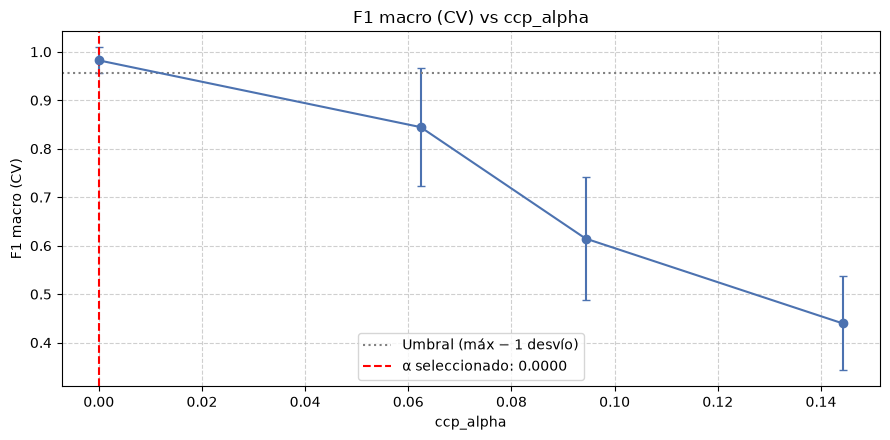

ccp_alpha seleccionado: 0.000000
Mejor F1 macro CV: 0.9823 (±0.0266)
Hojas antes: 6 | después: 6


In [41]:
# Ruta de complejidad de costo
path = arbol_sin_podar.cost_complexity_pruning_path(X_train_80, y_train_80)
ccp_alphas = path.ccp_alphas[:-1]   # el último α poda hasta la raíz, lo descartamos

medias, desvios = [], []
for alpha in ccp_alphas:
    clf_alpha = DecisionTreeClassifier(
        max_depth=grid_tree.best_params_['max_depth'],
        min_samples_split=grid_tree.best_params_['min_samples_split'],
        min_samples_leaf=grid_tree.best_params_['min_samples_leaf'],
        ccp_alpha=alpha, random_state=63)
    cv_scores = cross_val_score(clf_alpha, X_train_80, y_train_80,
                                cv=cv_strat, scoring='f1_macro')
    medias.append(cv_scores.mean())
    desvios.append(cv_scores.std())

df_alphas = pd.DataFrame({'ccp_alpha': ccp_alphas,
                          'F1_macro_CV': medias, 'Desvio': desvios})

# Regla del 1 desvío estándar
i_best = df_alphas['F1_macro_CV'].idxmax()
umbral = df_alphas.loc[i_best, 'F1_macro_CV'] - df_alphas.loc[i_best, 'Desvio']
alpha_seleccionado = df_alphas.loc[df_alphas['F1_macro_CV'] >= umbral, 'ccp_alpha'].max()

# Gráfico
plt.figure(figsize=(9, 4.5))
plt.errorbar(df_alphas['ccp_alpha'], df_alphas['F1_macro_CV'],
             yerr=df_alphas['Desvio'], marker='o', color='#4C72B0', capsize=3)
plt.axhline(umbral, color='gray', linestyle=':', label='Umbral (máx − 1 desvío)')
plt.axvline(alpha_seleccionado, color='red', linestyle='--',
            label=f'α seleccionado: {alpha_seleccionado:.4f}')
plt.title('F1 macro (CV) vs ccp_alpha')
plt.xlabel('ccp_alpha'); plt.ylabel('F1 macro (CV)')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout(); plt.show()

print(f"ccp_alpha seleccionado: {alpha_seleccionado:.6f}")
print(f"Mejor F1 macro CV: {df_alphas.loc[i_best,'F1_macro_CV']:.4f} (±{df_alphas.loc[i_best,'Desvio']:.4f})")

arbol_podado = DecisionTreeClassifier(
    max_depth=grid_tree.best_params_['max_depth'],
    min_samples_split=grid_tree.best_params_['min_samples_split'],
    min_samples_leaf=grid_tree.best_params_['min_samples_leaf'],
    ccp_alpha=alpha_seleccionado, random_state=63)
arbol_podado.fit(X_train_80, y_train_80)
print(f"Hojas antes: {arbol_sin_podar.get_n_leaves()} | después: {arbol_podado.get_n_leaves()}")

**Justificación del valor de `ccp_alpha` seleccionado:**
La curva muestra que el F1-Score Macro en CV es máximo (≈0.98) con `ccp_alpha = 0`. Ya el primer valor efectivo de α mayor que cero (≈0.06) hace caer el rendimiento (≈0.84) por debajo del umbral de la regla de 1 desvío estándar (≈0.96), y con valores mayores la caída es abrupta: la poda colapsa las divisiones que separan las clases de menor frecuencia (`DrogaA` frente a `DrogaB`, o `DrogaC` frente a `DrogaX`).

Por eso se selecciona $\alpha = 0$: la pre-poda (`max_depth=4`) ya dejó un árbol mínimo, donde cada hoja es necesaria, y la post-poda no elimina ninguna (6 hojas antes y después).

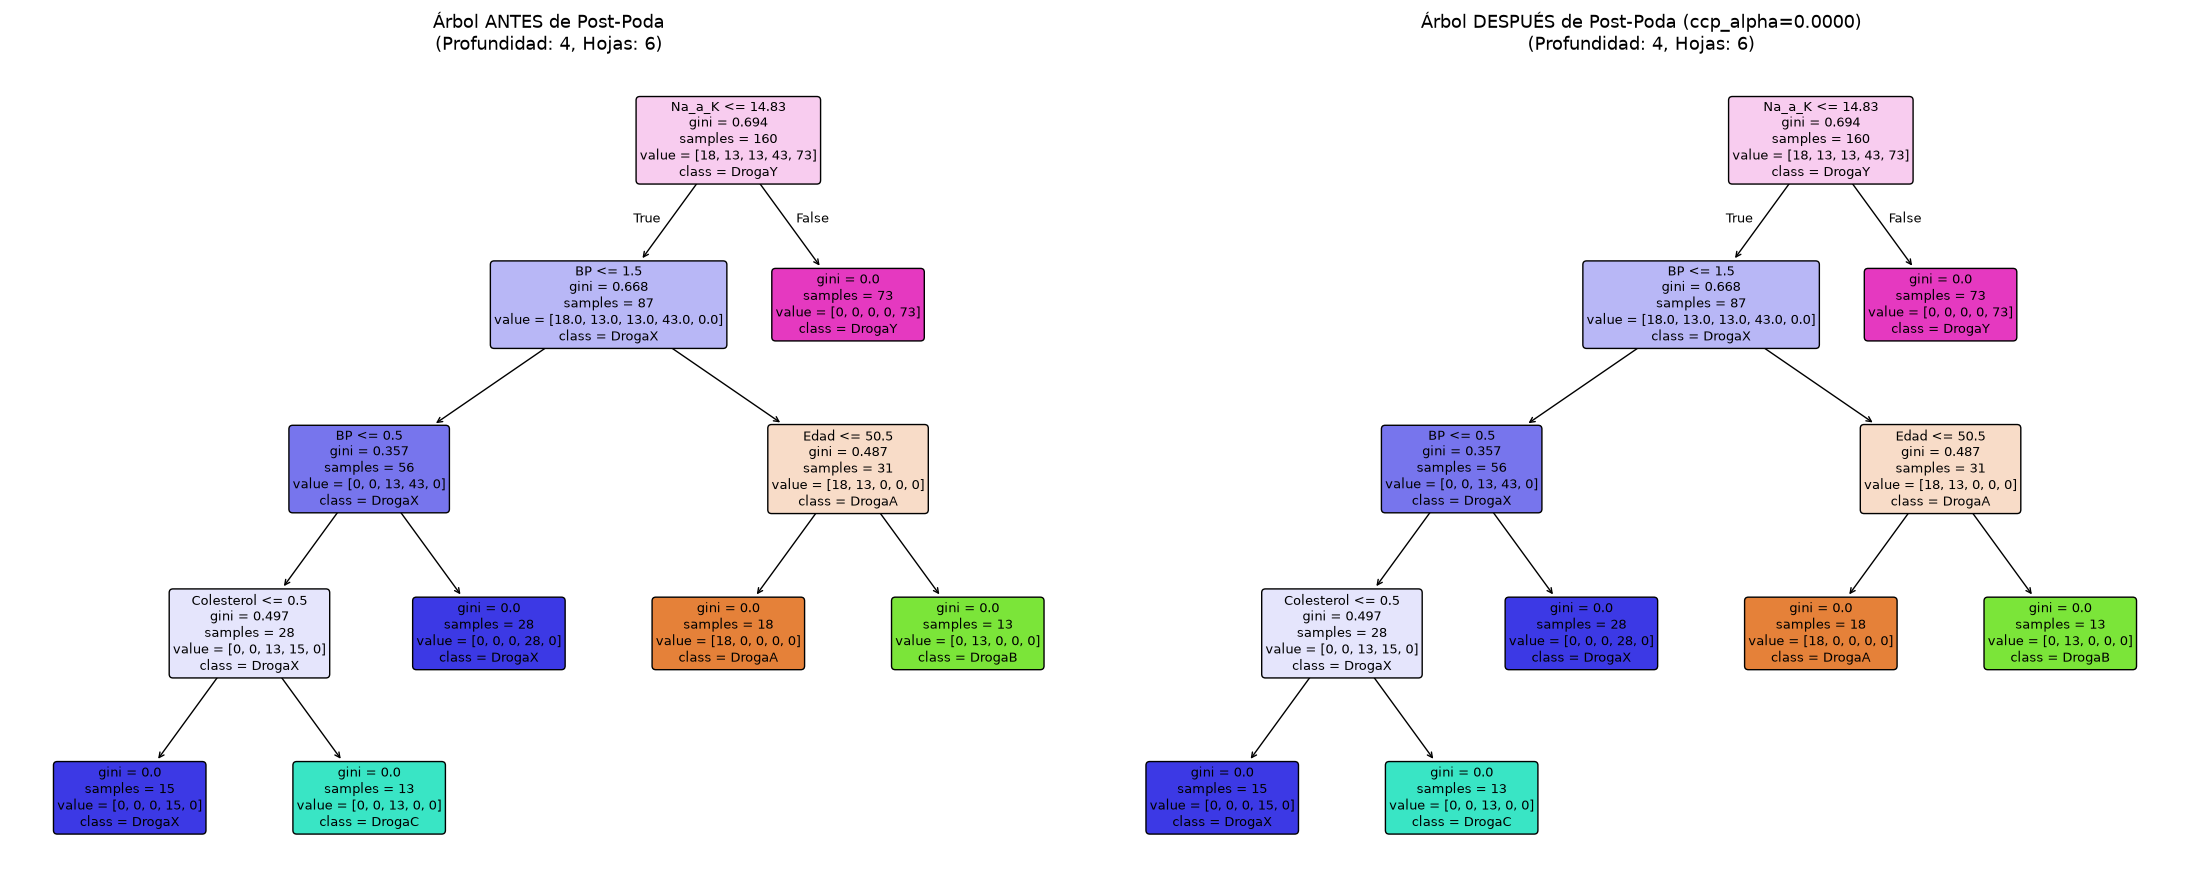

Reglas del Árbol de Clasificación Final (Post-Podado):
|--- Na_a_K <= 14.83
|   |--- BP <= 1.50
|   |   |--- BP <= 0.50
|   |   |   |--- Colesterol <= 0.50
|   |   |   |   |--- class: DrogaX
|   |   |   |--- Colesterol >  0.50
|   |   |   |   |--- class: DrogaC
|   |   |--- BP >  0.50
|   |   |   |--- class: DrogaX
|   |--- BP >  1.50
|   |   |--- Edad <= 50.50
|   |   |   |--- class: DrogaA
|   |   |--- Edad >  50.50
|   |   |   |--- class: DrogaB
|--- Na_a_K >  14.83
|   |--- class: DrogaY



In [42]:
# Gráfica 2: Comparación de árboles antes y después de post-poda
clases_nombres = arbol_podado.classes_.tolist()
features_nombres = X.columns.tolist()

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# Árbol antes de post-poda
plot_tree(
    arbol_sin_podar,
    feature_names=features_nombres,
    class_names=clases_nombres,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=axes[0]
)
axes[0].set_title(f"Árbol ANTES de Post-Poda\n(Profundidad: {arbol_sin_podar.get_depth()}, Hojas: {arbol_sin_podar.get_n_leaves()})", fontsize=13)

# Árbol después de post-poda
plot_tree(
    arbol_podado,
    feature_names=features_nombres,
    class_names=clases_nombres,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=axes[1]
)
axes[1].set_title(f"Árbol DESPUÉS de Post-Poda (ccp_alpha={alpha_seleccionado:.4f})\n(Profundidad: {arbol_podado.get_depth()}, Hojas: {arbol_podado.get_n_leaves()})", fontsize=13)

plt.tight_layout()
plt.show()

# Imprimimos las reglas en formato texto del árbol final
print("Reglas del Árbol de Clasificación Final (Post-Podado):")
print(export_text(arbol_podado, feature_names=features_nombres))

**Interpretación de la estructura del árbol:**
- **Raíz y corte principal**: El primer nodo evalúa invariablemente `Na_a_K <= 14.83`. Todos los pacientes con un cociente mayor son clasificados de forma pura en `DrogaY` (91 casos en total), confirmando la hipótesis del análisis exploratorio donde esta variable actúa como separador absoluto.
- **Ramas secundarias**: Para los pacientes con `Na_a_K <= 14.83`:
  - Si la presión arterial es alta (`BP > 1.5`), la decisión se bifurca estrictamente por la `Edad` (umbral en 50.5 años): menores o iguales reciben `DrogaA`, mayores reciben `DrogaB`.
  - Si la presión arterial no es alta (`BP <= 1.5`):
    - Pacientes con presión baja (`BP <= 0.5`) y `Colesterol == Alto` reciben `DrogaC`.
    - Pacientes con presión baja y colesterol normal, o con presión normal, reciben `DrogaX`.
- **Efecto de la post-poda**: No modifica el árbol (`ccp_alpha = 0`). El árbol final tiene 4 niveles de profundidad y 6 hojas: una por cada droga, salvo `DrogaX`, que aparece en dos hojas.

MÉTRICAS DEL ÁRBOL DE DECISIÓN EN AMBOS CONJUNTOS DE TEST:


,Modelo,Partición,Accuracy,Precision (Macro),Recall (Macro)
0,Árbol de Decisión (Post-Poda),80/20,1.0,1.0,1.0
1,Árbol de Decisión (Post-Poda),70/30,1.0,1.0,1.0


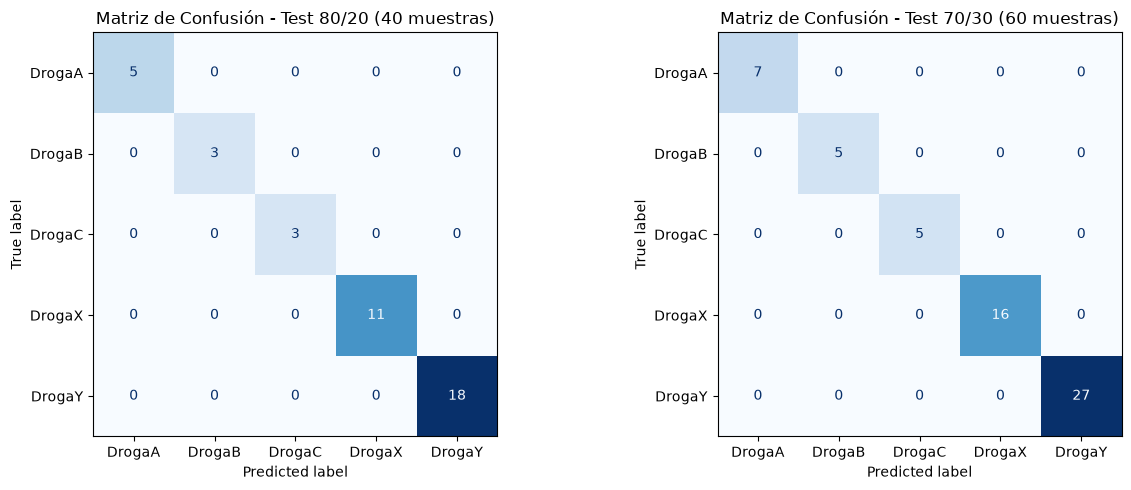

In [43]:
# Evaluamos el modelo en ambas particiones (80/20 y 70/30)
resultados_dt_test = []

# 1. Evaluación en Partición 80/20
pred_dt_80 = arbol_podado.predict(X_test_20)
resultados_dt_test.append({
    'Modelo': 'Árbol de Decisión (Post-Poda)',
    'Partición': '80/20',
    'Accuracy': round(accuracy_score(y_test_20, pred_dt_80), 4),
    'Precision (Macro)': round(precision_score(y_test_20, pred_dt_80, average='macro', zero_division=0), 4),
    'Recall (Macro)': round(recall_score(y_test_20, pred_dt_80, average='macro', zero_division=0), 4)
})

# 2. Evaluación en Partición 70/30 (Ajustamos el mismo estimador con los datos de Train 70/30)
arbol_podado_70 = DecisionTreeClassifier(
    max_depth=grid_tree.best_params_['max_depth'],
    min_samples_split=grid_tree.best_params_['min_samples_split'],
    min_samples_leaf=grid_tree.best_params_['min_samples_leaf'],
    ccp_alpha=alpha_seleccionado,
    random_state=63
)
arbol_podado_70.fit(X_train_70, y_train_70)
pred_dt_70 = arbol_podado_70.predict(X_test_30)

resultados_dt_test.append({
    'Modelo': 'Árbol de Decisión (Post-Poda)',
    'Partición': '70/30',
    'Accuracy': round(accuracy_score(y_test_30, pred_dt_70), 4),
    'Precision (Macro)': round(precision_score(y_test_30, pred_dt_70, average='macro', zero_division=0), 4),
    'Recall (Macro)': round(recall_score(y_test_30, pred_dt_70, average='macro', zero_division=0), 4)
})

df_dt_metricas = pd.DataFrame(resultados_dt_test)
print("MÉTRICAS DEL ÁRBOL DE DECISIÓN EN AMBOS CONJUNTOS DE TEST:")
display(df_dt_metricas)

# Gráfica 3: Matrices de Confusión sobre Test 80/20 y Test 70/30
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matriz 80/20
cm_80 = confusion_matrix(y_test_20, pred_dt_80, labels=clases_nombres)
disp_80 = ConfusionMatrixDisplay(confusion_matrix=cm_80, display_labels=clases_nombres)
disp_80.plot(cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title("Matriz de Confusión - Test 80/20 (40 muestras)")
axes[0].grid(False)

# Matriz 70/30
cm_70 = confusion_matrix(y_test_30, pred_dt_70, labels=clases_nombres)
disp_70 = ConfusionMatrixDisplay(confusion_matrix=cm_70, display_labels=clases_nombres)
disp_70.plot(cmap='Blues', ax=axes[1], colorbar=False)
axes[1].set_title("Matriz de Confusión - Test 70/30 (60 muestras)")
axes[1].grid(False)

plt.tight_layout()
plt.show()

**Interpretación de los resultados de prueba:**
- **Partición 80/20**: El modelo obtiene un rendimiento perfecto con **Exactitud (Accuracy) = 1.0000**, **Precisión Macro = 1.0000** y **Exhaustividad Macro = 1.0000**. La matriz de confusión es estrictamente diagonal, lo que indica cero falsos positivos y cero falsos negativos en todas las drogas.
- **Partición 70/30**: Con 140 muestras de entrenamiento y 60 de prueba el resultado es el mismo: exactitud, precisión y exhaustividad macro de 1.0000 y matriz de confusión diagonal.
- Las métricas macro coinciden con la exactitud global, por lo que el desbalance de clases no penalizó la identificación de las drogas menos frecuentes (`DrogaB` y `DrogaC`).
- Precaución: el conjunto es pequeño (200 pacientes, 40 o 60 en test) y las reglas que lo generan parecen deterministas, por lo que un 100% no garantiza el mismo desempeño con datos reales.

## Punto 5
Naive Bayes

In [44]:
# Borro las variables viejas del namespace para poder reutilizar los nombres
for v in ['X_train_70', 'X_test_30', 'y_train_70', 'y_test_30', 'X_encoded', 'y',
          'X_val_15', 'X_prueba_15', 'y_val_15', 'y_prueba_15',
          'X_train_80', 'X_test_20', 'y_train_80', 'y_test_20',
          'X_val_10', 'X_prueba_10', 'y_val_10', 'y_prueba_10']:
    globals().pop(v, None)

In [45]:
# Separo variable objetivo de datos
X_encoded = df.drop('Droga', axis=1)
y = df['Droga']

# Generación de las dos particiones solicitadas con random_state=63 y estratificación
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(
    X_encoded, y, test_size=0.20, random_state=63, stratify=y)
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X_encoded, y, test_size=0.30, random_state=63, stratify=y)

# Función auxiliar para calcular las métricas requeridas de forma consistente
def calcular_metricas(y_real, y_pred, modelo_nombre, particion_nombre):
    return {
        'Modelo': modelo_nombre,
        'Partición': particion_nombre,
        'Accuracy': round(accuracy_score(y_real, y_pred), 4),
        'Precision (Macro)': round(precision_score(y_real, y_pred, average='macro', zero_division=0), 4),
        'Recall (Macro)': round(recall_score(y_real, y_pred, average='macro', zero_division=0), 4),
        'F1-Score (Macro)': round(f1_score(y_real, y_pred, average='macro', zero_division=0), 4)}

## Actividad 5: Clasificación con Bayes Ingenuo (Naive Bayes)

Para este problema se evalúan dos estrategias de modelado:
1. **Datos continuos con GaussianNB**: Aplica distribuciones normales sobre los atributos numéricos continuos (`Edad` y `Na_a_K`).
2. **Discretización por cuantiles (Equal-Frequency) con CategoricalNB**: Se discretizan los atributos continuos en 3 y 5 intervalos utilizando cuantiles para equilibrar la cantidad de registros por intervalo. El estimador se ajusta únicamente sobre el conjunto de entrenamiento y se aplica sobre el conjunto de prueba para evitar fuga de información (*data leakage*).

Ambos enfoques se comparan en las dos particiones (80/20 y 70/30) evaluando Exactitud, Precisión macro y Exhaustividad macro.

In [46]:
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

nb_results = []
particiones = [
    ('80/20', X_train_80, X_test_20, y_train_80, y_test_20),
    ('70/30', X_train_70, X_test_30, y_train_70, y_test_30)
]

cols_continuas = ['Edad', 'Na_a_K']
cols_categoricas = ['Sexo', 'BP', 'Colesterol']

modelos_evaluados_nb = {}

for nombre_part, X_tr, X_ts, y_tr, y_ts in particiones:
    # 1. Enfoque Continuo: GaussianNB
    gnb = GaussianNB()
    gnb.fit(X_tr, y_tr)
    pred_gnb = gnb.predict(X_ts)
    nb_results.append(calcular_metricas(y_ts, pred_gnb, 'GaussianNB', nombre_part))
    modelos_evaluados_nb[f'GaussianNB_{nombre_part}'] = (gnb, y_ts, pred_gnb)

    # 2. Enfoque Discretizado con 3 y 5 intervalos (Equal-Frequency)
    for n_bins in [3, 5]:
        discretizer = KBinsDiscretizer(n_bins=n_bins, encode='ordinal', strategy='quantile', subsample=None)

        # Ajustamos el discretizador únicamente en Train y transformamos Train y Test
        X_tr_cont_disc = discretizer.fit_transform(X_tr[cols_continuas])
        X_ts_cont_disc = discretizer.transform(X_ts[cols_continuas])

        # Reconstruimos la matriz con todos los atributos discretos
        X_tr_disc = np.hstack([X_tr[cols_categoricas].values, X_tr_cont_disc])
        X_ts_disc = np.hstack([X_ts[cols_categoricas].values, X_ts_cont_disc])

        cnb = CategoricalNB(alpha=1.0)
        cnb.fit(X_tr_disc, y_tr)
        pred_cnb = cnb.predict(X_ts_disc)

        nombre_mod = f'CategoricalNB ({n_bins} cuantiles)'
        nb_results.append(calcular_metricas(y_ts, pred_cnb, nombre_mod, nombre_part))
        modelos_evaluados_nb[f'{nombre_mod}_{nombre_part}'] = (cnb, y_ts, pred_cnb)

# Tabla de resultados comparativa para Naive Bayes
res_nb = nb_results
df_nb_results = pd.DataFrame(nb_results)
df_nb_results

,Modelo,Partición,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,GaussianNB,80/20,0.8500,0.8311,0.9333,0.8529
1,CategoricalNB (3 cuantiles),80/20,0.8250,0.8305,0.8111,0.8087
2,CategoricalNB (5 cuantiles),80/20,0.9250,0.9262,0.9667,0.9398
3,GaussianNB,70/30,0.8833,0.8523,0.9481,0.8796
4,CategoricalNB (3 cuantiles),70/30,0.8500,0.9021,0.8305,0.8519
5,CategoricalNB (5 cuantiles),70/30,0.9167,0.9000,0.9630,0.9246


### Análisis de resultados en Naive Bayes
Al comparar las aproximaciones:
- **GaussianNB** asume que las variables continuas provienen de distribuciones gaussianas. Dado que `Na_a_K` tiene una asimetría hacia la derecha y no es estrictamente gaussiana, esta hipótesis introduce solapamiento en las probabilidades posteriores y confunde pacientes de `DrogaY` con otras drogas (6 errores sobre 40 en 80/20 y 7 sobre 60 en 70/30).
- **CategoricalNB con 5 cuantiles** es la mejor variante: captura de forma más fina el punto de quiebre de `Na_a_K` (en torno a 14.8-15) y de la `Edad`, con 3 errores sobre 40 (80/20) y 5 sobre 60 (70/30).
- **CategoricalNB con 3 cuantiles** discretiza de forma demasiado gruesa y rinde peor que GaussianNB (7 errores sobre 40 y 9 sobre 60). La discretización solo ayuda si los intervalos son suficientemente finos.
- La diferencia entre las particiones 80/20 y 70/30 es pequeña y no concluyente (conjuntos de test de 40 y 60 pacientes): con CategoricalNB de 5 cuantiles la exactitud es 0.925 y 0.917, y GaussianNB resulta algo mejor en 70/30.

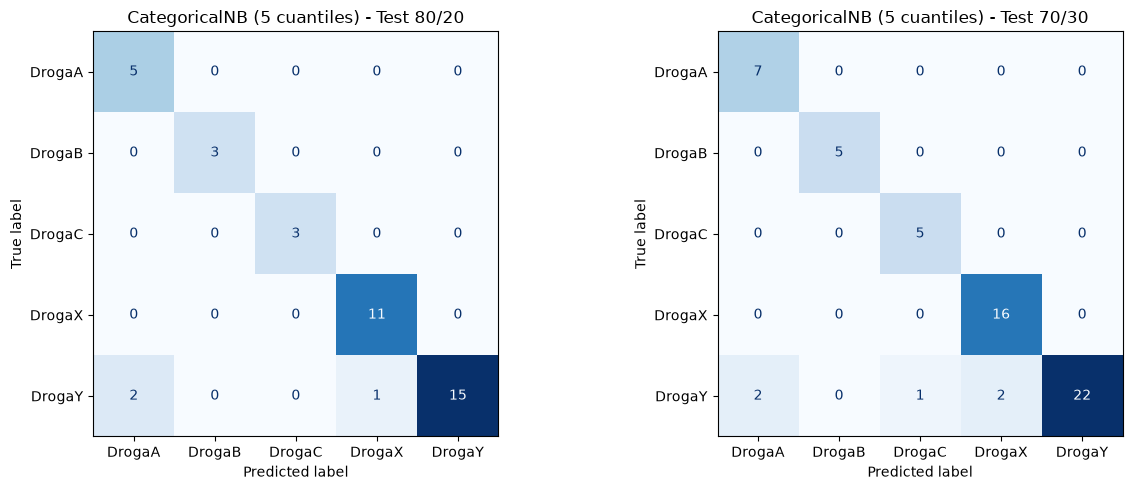

In [47]:
# Graficamos las matrices de confusión del mejor enfoque de Naive Bayes (80/20 y 70/30)
clases_orden = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, nombre_part in enumerate(['80/20', '70/30']):
    clave = f'CategoricalNB (5 cuantiles)_{nombre_part}'
    _, y_real, y_pred = modelos_evaluados_nb[clave]

    cm = confusion_matrix(y_real, y_pred, labels=clases_orden)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases_orden)
    disp.plot(cmap='Blues', ax=axes[i], colorbar=False)
    axes[i].set_title(f'CategoricalNB (5 cuantiles) - Test {nombre_part}')
    axes[i].grid(False)

plt.tight_layout()
plt.show()

**Interpretación de las matrices de confusión observadas:**
- Todos los errores de GaussianNB y de CategoricalNB con 5 cuantiles son pacientes que realmente reciben `DrogaY` y se predicen como `DrogaA`, `DrogaC` o `DrogaX`. Las demás clases se clasifican sin errores. Con 3 cuantiles, los intervalos gruesos generan además algunos pacientes de `DrogaB`, `DrogaC` y `DrogaX` predichos como `DrogaY`.
- Esto ocurre por el supuesto de independencia condicional: el modelo combina `Na_a_K`, `Edad`, `BP` y `Colesterol` de forma multiplicativa, sin capturar que `Na_a_K > 14.8` determina `DrogaY` sin importar el resto. Los pacientes de `DrogaY` cuyo perfil se parece al de otra droga en las demás variables son arrastrados hacia esa droga.

## K-nn

## Actividad 6: Clasificación con k-NN (K-Nearest Neighbors)

### Normalización / Estandarización de atributos
Dado que k-NN calcula distancias geométricas entre instancias en el espacio de características, las variables con escalas grandes (`Edad` con rango 15-74 y `Na_a_K` con rango 6-38) dominarían completamente sobre los atributos binarios o ternarios codificados (`Sexo`, `Colesterol`, `BP`).
Por ello, es estrictamente necesario **estandarizar las variables numéricas** (`StandardScaler`), ajustando la escala únicamente en el conjunto de entrenamiento y transformando el conjunto de prueba correspondiente.

Se explora una grilla sistemática con:
- Vecinos ($k$): 1, 3, 5, 7, 9, 11
- Métricas de distancia: Euclidiana y Manhattan

In [48]:
cols_cont = ['Edad', 'Na_a_K']
def buscar_cv(pipe, grid, X_tr, y_tr):
    gs = GridSearchCV(pipe, grid, cv=cv_strat, scoring='f1_macro', n_jobs=-1)
    return gs.fit(X_tr, y_tr)

pipe_knn = Pipeline([
    ('prep', ColumnTransformer([('esc', StandardScaler(), cols_cont)], remainder='passthrough')),
    ('knn', KNeighborsClassifier())])
grid_knn = {'knn__n_neighbors': [1, 3, 5, 7, 9, 11],
            'knn__metric': ['euclidean', 'manhattan']}

res_knn, mejores_knn = [], {}
for nombre_part, X_tr, X_ts, y_tr, y_ts in particiones:
    gs = buscar_cv(pipe_knn, grid_knn, X_tr, y_tr)
    pred = gs.predict(X_ts)
    mejores_knn[nombre_part] = (gs, y_ts, pred)
    k, m = gs.best_params_['knn__n_neighbors'], gs.best_params_['knn__metric']
    res_knn.append(calcular_metricas(y_ts, pred, f'k-NN (k={k}, {m})', nombre_part))

display(pd.DataFrame(res_knn))

,Modelo,Partición,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,"k-NN (k=1, manhattan)",80/20,0.875,0.8700,0.9374,0.8969
1,"k-NN (k=11, manhattan)",70/30,0.900,0.9156,0.9230,0.9101


In [49]:
# Evolución de k-NN: se evalúa cada combinación (k, métrica de distancia) en cada partición
from sklearn.metrics import f1_score

k_valores = [1, 3, 5, 7, 9, 11]
metricas_dist = ['euclidean', 'manhattan']
clases_orden = sorted(y.unique())

filas_curvas = []
modelos_evaluados_knn = {}
for nombre_part, X_tr, X_ts, y_tr, y_ts in particiones:
    for metrica in metricas_dist:
        for k in k_valores:
            modelo = Pipeline([
                ('prep', ColumnTransformer([('esc', StandardScaler(), cols_cont)], remainder='passthrough')),
                ('knn', KNeighborsClassifier(n_neighbors=k, metric=metrica))])
            modelo.fit(X_tr, y_tr)
            pred = modelo.predict(X_ts)
            modelos_evaluados_knn[f'{nombre_part}_{metrica}_k{k}'] = (modelo, y_ts, pred)
            filas_curvas.append({'Partición': nombre_part, 'k': k, 'Métrica': metrica,
                                 'F1 (Macro)': f1_score(y_ts, pred, average='macro')})
df_curvas_knn = pd.DataFrame(filas_curvas)


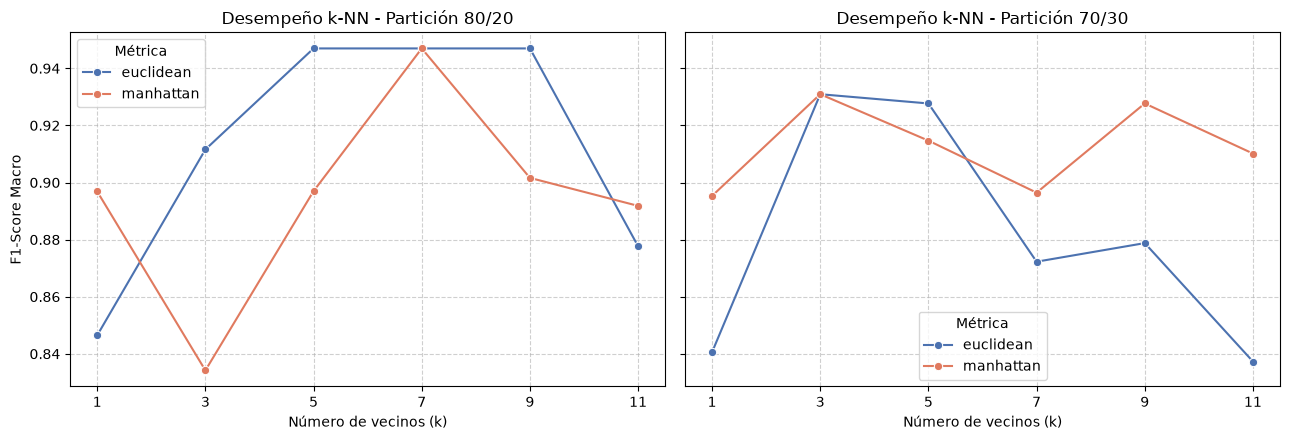

In [50]:
# Gráfica 1 de k-NN: Desempeño vs número de vecinos k
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for i, nombre_part in enumerate(['80/20', '70/30']):
    datos_part = df_curvas_knn[df_curvas_knn['Partición'] == nombre_part]
    sns.lineplot(
        data=datos_part,
        x='k',
        y='F1 (Macro)',
        hue='Métrica',
        marker='o',
        ax=axes[i],
        palette={'euclidean': '#4C72B0', 'manhattan': '#E07A5F'})
    axes[i].set_title(f'Desempeño k-NN - Partición {nombre_part}')
    axes[i].set_xlabel('Número de vecinos (k)')
    axes[i].set_ylabel('F1-Score Macro')
    axes[i].set_xticks(k_valores)
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Interpretación de la evolución con respecto a $k$ y la métrica de distancia:**
- No hay una métrica claramente superior. En la partición 70/30, Manhattan iguala o supera a la Euclidiana en la mayoría de los valores de $k$. En la 80/20 ocurre lo contrario: la Euclidiana es mejor en $k=3, 5$ y $9$.
- Con $k=1$ el desempeño es el menor (F1 macro ≈ 0.85-0.90), porque el modelo es muy sensible al ruido. Los mejores valores (F1 macro ≈ 0.93-0.95) aparecen con $k$ intermedios ($k=3$ en 70/30; $k=5$ a $9$ en 80/20). Con la distancia Euclidiana, $k=11$ vuelve a bajar el desempeño.
- El conjunto de test es pequeño (40 y 60 pacientes): un solo paciente mueve la exactitud entre 2.5 y 1.7 puntos. Las diferencias entre configuraciones deben leerse con cautela.

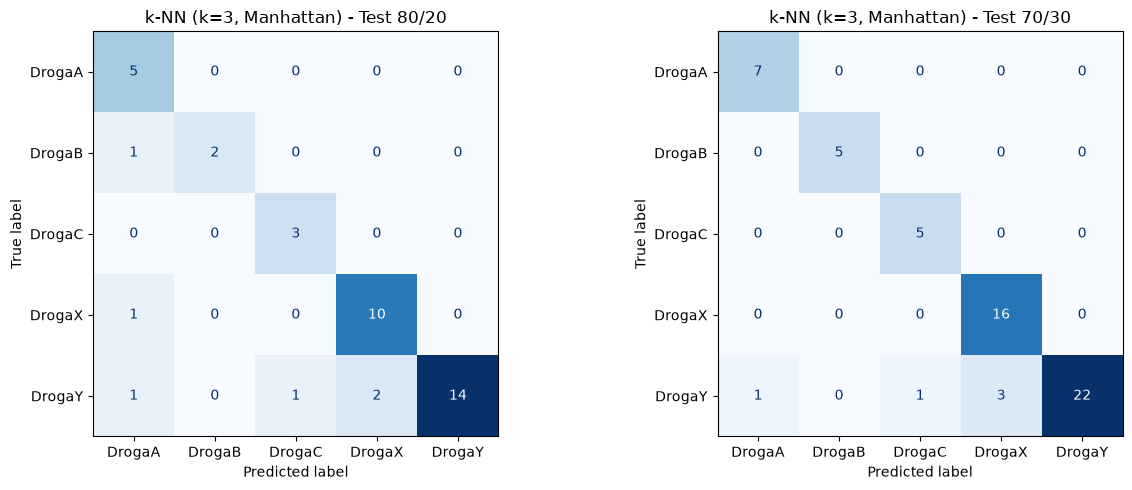

In [51]:
# Gráfica 2 de k-NN: Matrices de confusión del mejor k-NN (k=3, manhattan)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, nombre_part in enumerate(['80/20', '70/30']):
    clave = f'{nombre_part}_manhattan_k3'
    _, y_real, y_pred = modelos_evaluados_knn[clave]

    cm = confusion_matrix(y_real, y_pred, labels=clases_orden)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases_orden)
    disp.plot(cmap='Blues', ax=axes[i], colorbar=False)
    axes[i].set_title(f'k-NN (k=3, Manhattan) - Test {nombre_part}')
    axes[i].grid(False)

plt.tight_layout()
plt.show()

**Interpretación de las matrices de confusión observadas ($k=3$, Manhattan):**
- Las clases `DrogaA`, `DrogaB`, `DrogaC` y `DrogaX` se reconocen casi siempre. Los errores se concentran en pacientes de `DrogaY` clasificados como `DrogaA`, `DrogaC` o `DrogaX` (4 de 18 en 80/20 y 5 de 28 en 70/30).
- En 80/20 hay además un paciente de `DrogaB` predicho como `DrogaA` y uno de `DrogaX` predicho como `DrogaA`.
- Esto se debe a que la distancia mezcla todas las variables con el mismo peso y no refleja que `Na_a_K > 14.8` define por sí sola a `DrogaY`.

## Comparacion de modelos


## Actividad 7: Comparación integral de modelos de clasificación

En esta sección se construye la tabla comparativa de los tres algoritmos evaluados sobre ambos conjuntos de prueba (80/20 y 70/30), considerando la mejor configuración hallada para cada uno:
1. **Árbol de Decisión**: Configuración con poda/profundidad óptima identificada en la Actividad 4.
2. **Bayes Ingenuo**: la mejor variante de CategoricalNB (discretización por cuantiles; resultó la de 5 intervalos).
3. **k-NN**: el mejor $k$ y la mejor métrica elegidos por validación cruzada sobre el conjunto de entrenamiento (con características estandarizadas): $k=1$ en la partición 80/20 y $k=11$ en la 70/30, ambos con distancia Manhattan.

In [52]:
# Árbol de Decisión: reutilizamos las predicciones del árbol podado (celda 92)
dt_metrics = [
    calcular_metricas(y_test_20, pred_dt_80, 'Árbol de Decisión (podado)', '80/20'),
    calcular_metricas(y_test_30, pred_dt_70, 'Árbol de Decisión (podado)', '70/30'),
]

# Mejor CategoricalNB de cada partición (el de res_nb que no es GaussianNB)
nb_best_80 = max((r for r in res_nb if r['Partición'] == '80/20' and r['Modelo'].startswith('Categorical')), key=lambda r: r['F1-Score (Macro)'])
nb_best_70 = max((r for r in res_nb if r['Partición'] == '70/30' and r['Modelo'].startswith('Categorical')), key=lambda r: r['F1-Score (Macro)'])

# Mejor k-NN de cada partición (ya elegido por CV)
knn_best_80 = next(r for r in res_knn if r['Partición'] == '80/20')
knn_best_70 = next(r for r in res_knn if r['Partición'] == '70/30')

# Consolidamos la tabla comparativa final
filas_comparativas = [
    dt_metrics[0],
    dt_metrics[1],
    {k: nb_best_80[k] for k in dt_metrics[0].keys()},
    {k: nb_best_70[k] for k in dt_metrics[0].keys()},
    {k: knn_best_80[k] for k in dt_metrics[0].keys()},
    {k: knn_best_70[k] for k in dt_metrics[0].keys()},
]

df_comparativo = pd.DataFrame(filas_comparativas)
df_comparativo.sort_values(by=['Partición', 'Accuracy', 'F1-Score (Macro)'], ascending=[True, False, False], inplace=True)
df_comparativo.reset_index(drop=True, inplace=True)

print("TABLA COMPARATIVA FINAL DE RENDIMIENTO:")
display(df_comparativo)

TABLA COMPARATIVA FINAL DE RENDIMIENTO:


,Modelo,Partición,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
0,Árbol de Decisión (podado),70/30,1.0000,1.0000,1.0000,1.0000
1,CategoricalNB (5 cuantiles),70/30,0.9167,0.9000,0.9630,0.9246
2,"k-NN (k=11, manhattan)",70/30,0.9000,0.9156,0.9230,0.9101
3,Árbol de Decisión (podado),80/20,1.0000,1.0000,1.0000,1.0000
4,CategoricalNB (5 cuantiles),80/20,0.9250,0.9262,0.9667,0.9398
5,"k-NN (k=1, manhattan)",80/20,0.8750,0.8700,0.9374,0.8969


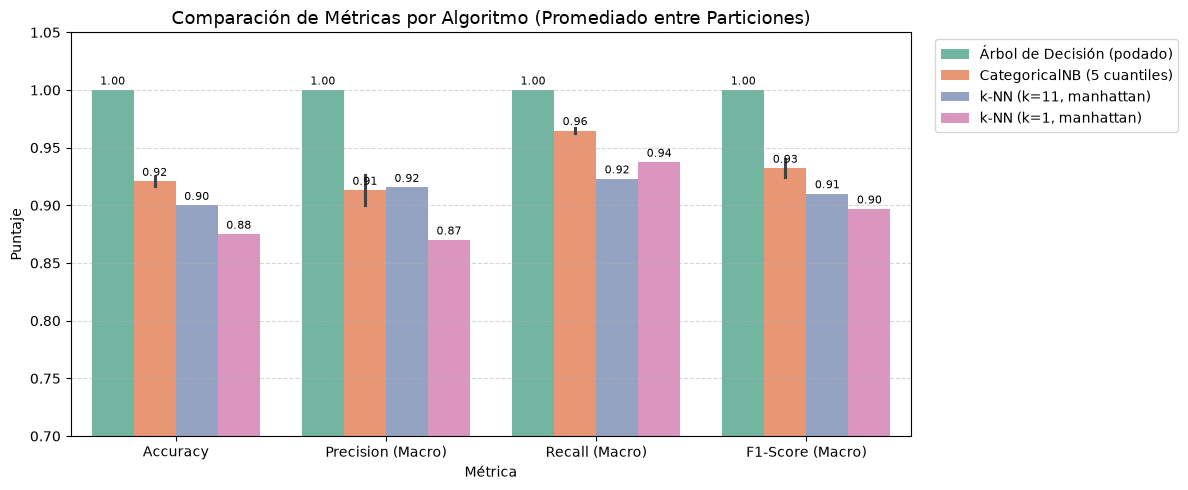

In [53]:
# Gráfico comparativo de desempeño entre algoritmos
df_plot = df_comparativo.melt(
    id_vars=['Modelo', 'Partición'],
    value_vars=['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)'],
    var_name='Métrica',
    value_name='Valor'
)

plt.figure(figsize=(12, 5))
g = sns.barplot(
    data=df_plot,
    x='Métrica',
    y='Valor',
    hue='Modelo',
    palette='Set2'
)
plt.title('Comparación de Métricas por Algoritmo (Promediado entre Particiones)', fontsize=13)
plt.ylabel('Puntaje')
plt.ylim(0.70, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

for p in g.patches:
    height = p.get_height()
    if height > 0:
        g.annotate(f'{height:.2f}',
                   (p.get_x() + p.get_width() / 2., height),
                   ha='center', va='bottom',
                   fontsize=8, color='black',
                   xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()

### Selección y justificación del modelo más adecuado

Al contrastar los tres clasificadores bajo el compromiso entre **desempeño predictivo** e **interpretabilidad**, el **Árbol de Decisión** resulta la opción óptima para este problema por los siguientes fundamentos:

1. **Rendimiento métrico superior**:
   - El Árbol de Decisión alcanza un **100% de Exactitud, Precisión macro y Recall macro** en ambas particiones (80/20 y 70/30).
   - Naive Bayes con 5 cuantiles queda en segundo lugar (Accuracy ≈ 92%), seguido por k-NN (Accuracy ≈ 87.5-90%). Naive Bayes sufre por la violación del supuesto de independencia entre atributos, y k-NN por tratar todas las variables con el mismo peso.
   - Con solo 40 o 60 pacientes de test, estas diferencias equivalen a unos pocos pacientes: son orientativas, no definitivas.

2. **Interpretabilidad y valor clínico**:
   - En el ámbito médico-farmacológico, la justificación de una prescripción no puede ser una "caja negra".
   - El Árbol de Decisión genera un conjunto de reglas deterministas, jerárquicas y transparentes que reflejan fielmente el protocolo clínico del conjunto de datos:
     $$\text{Si } Na\_a\_K > 14.8 \implies \text{DrogaY}$$
     $$\text{Si } Na\_a\_K \le 14.8 \land BP = \text{Alto} \land Edad \le 50 \implies \text{DrogaA}$$
     $$\text{Si } Na\_a\_K \le 14.8 \land BP = \text{Alto} \land Edad > 50 \implies \text{DrogaB}$$
     $$\text{Si } Na\_a\_K \le 14.8 \land BP = \text{Bajo} \land Colesterol = \text{Alto} \implies \text{DrogaC}$$
     $$\text{Si } Na\_a\_K \le 14.8 \land ((BP = \text{Bajo} \land Colesterol = \text{Normal}) \lor BP = \text{Normal}) \implies \text{DrogaX}$$
   - Por el contrario, **k-NN** requiere almacenar todo el conjunto de entrenamiento, depende de un escalado geométrico artificial y no provee reglas explícitas de asignación.
   - **Naive Bayes** asigna probabilidades atomizadas por variable y falla al capturar reglas de corte condicionales anidadas.

Por ende, el **Árbol de Decisión** es el modelo elegido tanto por su rendimiento como por su completa auditabilidad para el personal de salud.

# Conclusiones Generales

A lo largo del presente trabajo práctico se abordaron dos problemas de minería de datos con distintas naturalezas:

### 1. Problema de Regresión (Comportamiento Financiero de Empresas - `Profit`)
- El análisis exploratorio identificó una correlación positiva casi perfecta entre la inversión en I+D (`RyD_Spend`) y la ganancia (`Profit`), así como una colinealidad crítica entre `RyD_Spend` y `MarketingSpend`.
- La eliminación justificada de los 3 valores atípicos severos y la exclusión de `MarketingSpend` permitieron simplificar la dimensionalidad del espacio sin perder capacidad predictiva.
- El modelo `DecisionTreeRegressor` demostró que una profundidad acotada es suficiente para capturar la estructura de la función de beneficio, alcanzando un error cuadrático medio significativamente bajo y confirmando a `RyD_Spend` como el factor de mayor ganancia de información.

### 2. Problema de Clasificación (Prescripción de Fármacos - `Droga`)
- Se identificó un desbalance de clases marcado, donde `DrogaY` representa casi la mitad del conjunto de datos, lo que justificó el uso obligatorio de métricas macro (Precision y Recall macro) y particiones estratificadas.
- La relación sodio-potasio (`Na_a_K`) actúa como el divisor primario y absoluto para la clase mayoritaria (`DrogaY`).
- La estandarización de variables demostró ser un paso obligatorio para el algoritmo k-NN para evitar el sesgo de escala de las variables continuas sobre las categóricas, mientras que para árboles de decisión no fue necesaria debido a su propiedad de invarianza ante transformaciones monótonas.
- Para Naive Bayes, la discretización por cuantiles solo mejoró la estimación respecto a `GaussianNB` con 5 intervalos (Accuracy ≈ 92%); con 3 intervalos fue peor. Con 5 intervalos, todos sus errores fueron pacientes de `DrogaY`, y el modelo siguió limitado por la hipótesis de independencia condicional.
- k-NN (Accuracy ≈ 87.5-90%) no mostró una métrica de distancia ni un $k$ claramente superiores, y también confundió pacientes de `DrogaY`.
- El **Árbol de Decisión** resultó ser el algoritmo más eficaz y adecuado, logrando un compromiso ideal entre precisión predictiva (100% en ambas particiones) y simplicidad de interpretación para la toma de decisiones clínicas.